# Homework 2: A/B Testing
Roman Ghukasyan

## Experiment
I compare four ads with mean rewards 1, 2, 3, and 4. Each algorithm runs for 20,000 trials with normal rewards of variance 1. Epsilon-Greedy uses epsilon = 1/t. Thompson Sampling uses known precision 1 and starts each ad with a Normal(0, 1) prior for its mean. The random seed is 42.

The implementation and full experiment workflow are in `Bandit.py`.

In [1]:
from IPython.display import Image, display
from Bandit import main, OUTPUT_DIR

main()

2026-11-17 20:57:02.331 +04:00 | INFO     | Bandit:main:335 - Running Epsilon-Greedy: 20000 trials, epsilon = 1/t
2026-11-17 20:57:02.423 +04:00 | INFO     | Bandit:report:131 - Epsilon-Greedy cumulative reward: 79734.47
2026-11-17 20:57:02.423 +04:00 | INFO     | Bandit:report:132 - Epsilon-Greedy cumulative regret: 135.00
2026-11-17 20:57:02.424 +04:00 | INFO     | Bandit:report:133 - Epsilon-Greedy average reward: 3.9867
2026-11-17 20:57:02.424 +04:00 | INFO     | Bandit:report:134 - Epsilon-Greedy average regret: 0.0067
2026-11-17 20:57:02.457 +04:00 | INFO     | Bandit:report:138 - Saved 20000 Epsilon-Greedy rewards to rewards.csv
2026-11-17 20:57:02.457 +04:00 | DEBUG    | Bandit:main:340 - Epsilon-Greedy pulls per ad: [4, 1, 121, 19874]
2026-11-17 20:57:02.458 +04:00 | INFO     | Bandit:main:342 - Running Thompson Sampling: 20000 trials, precision = 1.0
2026-11-17 20:57:02.622 +04:00 | INFO     | Bandit:report:227 - Thompson Sampling cumulative reward: 80058.97
2026-11-17 20:57:

## Learning process
The plots show each ad's estimated mean reward on linear and logarithmic trial axes. The logarithmic scale makes the early trials easier to see.

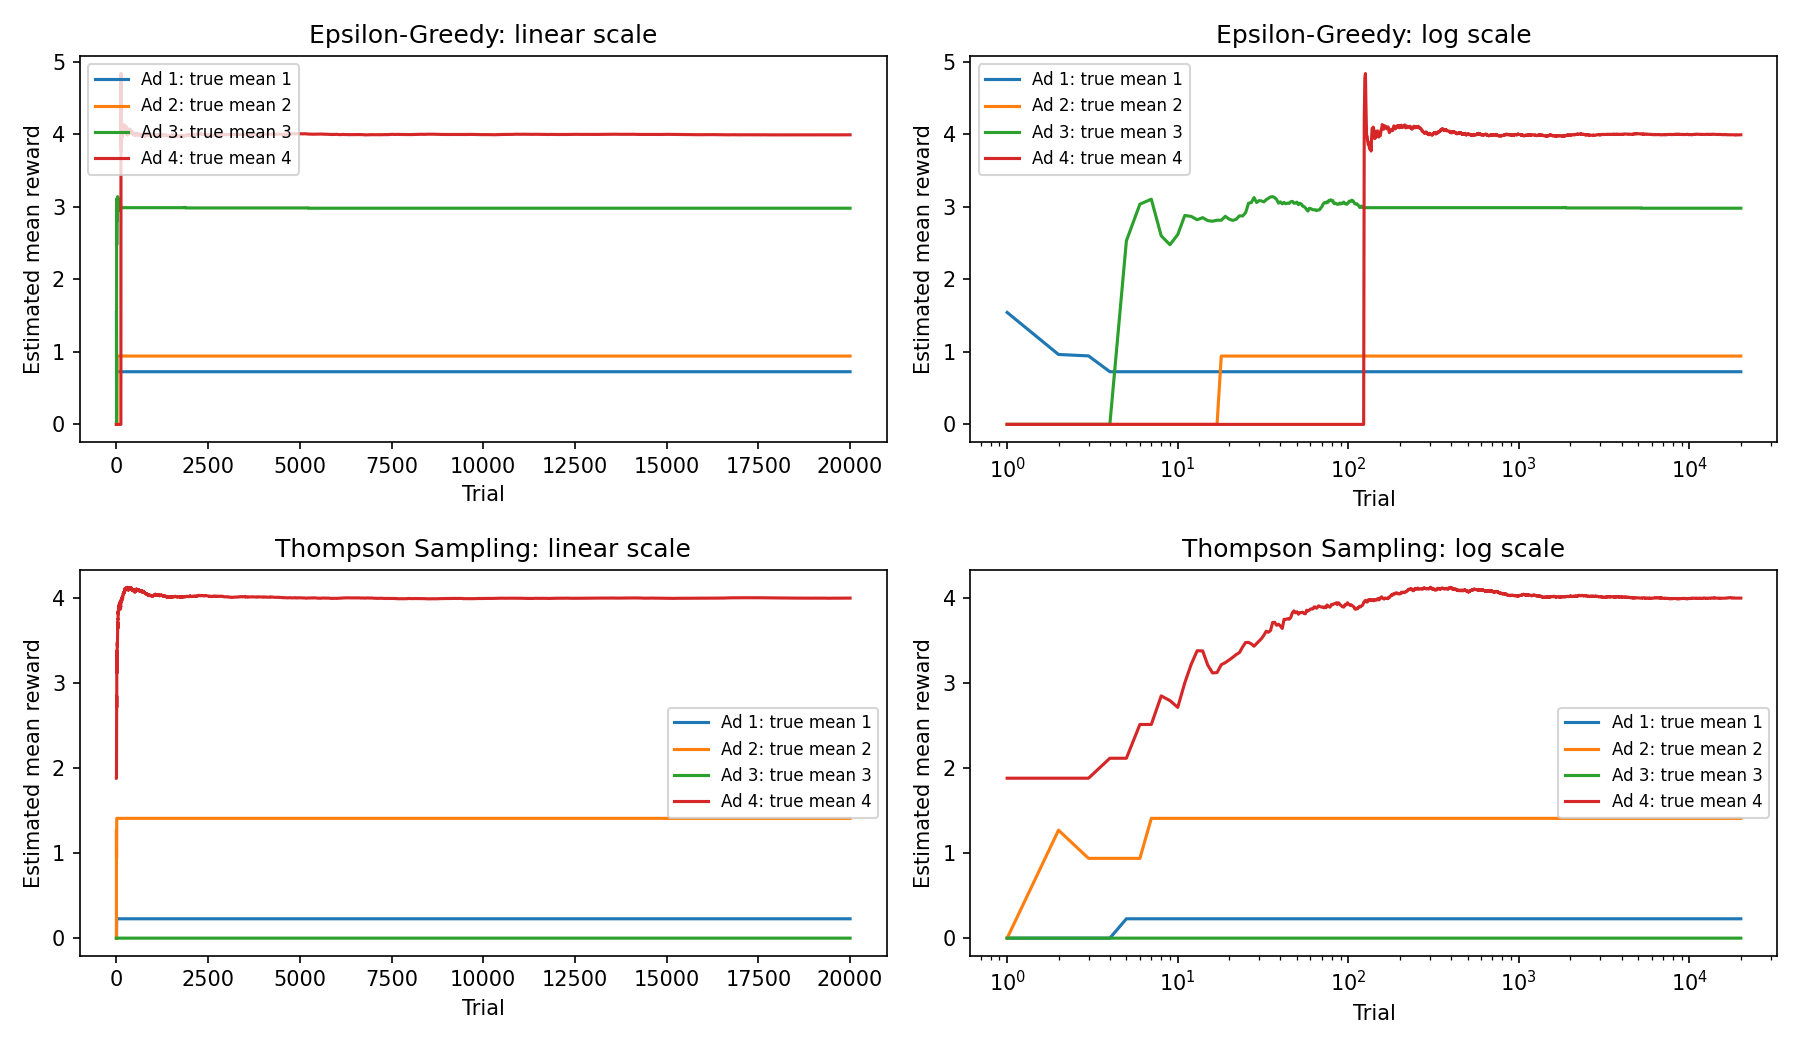

In [2]:
display(Image(filename=str(OUTPUT_DIR / "plots" / "learning_process.png")))

## Cumulative rewards and regrets
Cumulative reward is the sum of observed rewards. At each trial, regret is 4 minus the true mean reward of the selected ad. Cumulative regret is the sum of these losses and is nonnegative.

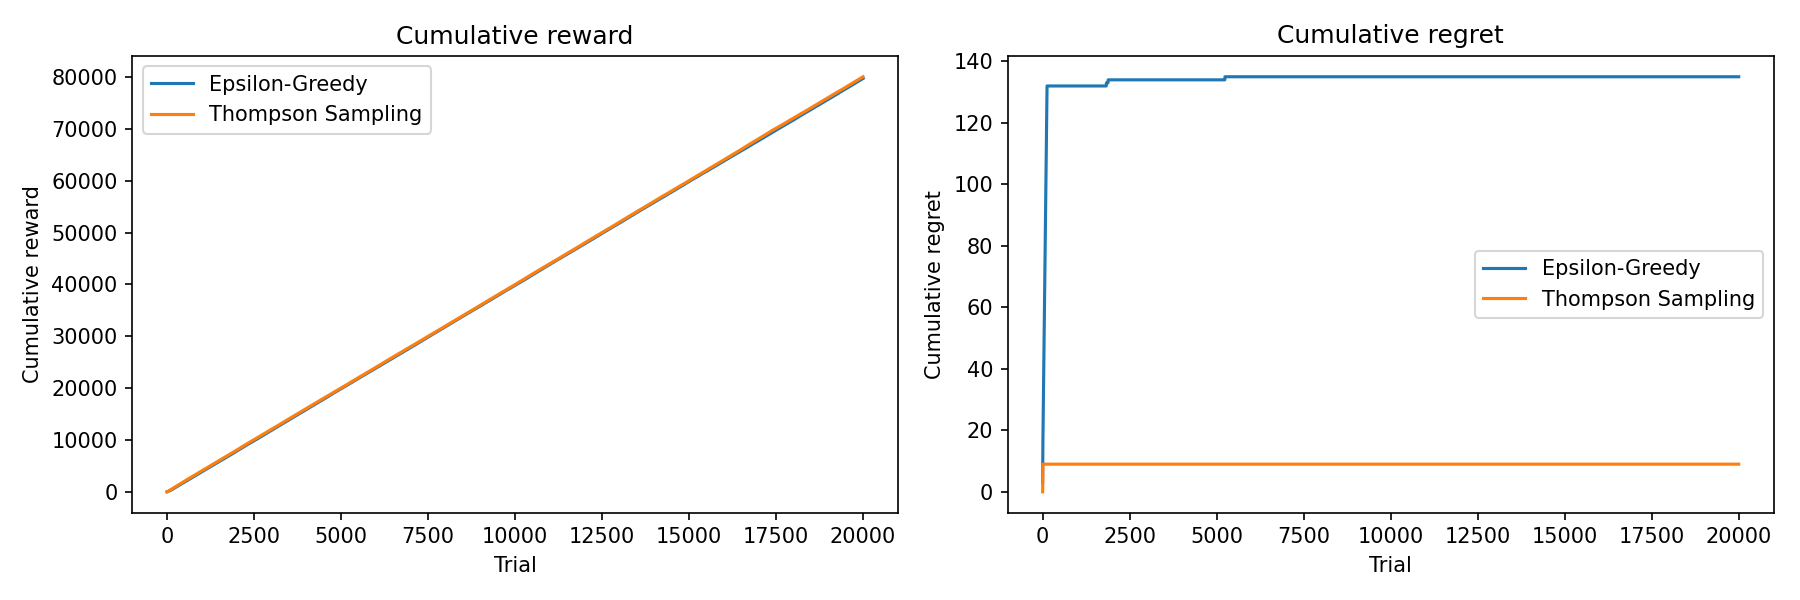

In [3]:
display(Image(filename=str(OUTPUT_DIR / "plots" / "cumulative_comparison.png")))

Epsilon-Greedy earned 79,734.47 with cumulative regret 135. Thompson Sampling earned 80,058.97 with cumulative regret 9. Thompson Sampling performed better in this run. The result can change with a different random seed.

## Bonus: better implementation plan
- Pull each ad once at the beginning so every ad has an initial estimate.
- Use epsilon = min(1, 10/t) to explore more before relying on the current best ad. This can reduce mistakes from early rewards, but extra exploration also has a cost.
- Repeat both experiments with different random seeds and compare their average cumulative rewards and regrets. This makes the comparison less dependent on one random run.